# TRL

This little example demonstrates how to use scikit-rf for a basic TRL calibration. 

## Basic Use 

### Imports 

First we import `skrf`, the `TRL` class, and setup matplotlib plotting. 

In [1]:
import skrf as rf
from skrf.calibration import TRL

%matplotlib inline
from skrf.plotting import stylely

stylely()

###  Load the data 

Load the calibration standard's measurements and the switch terms from touchstone files. ( If you dont know what switch terms are, see [this section below](#Switch-Terms). )

In [2]:
T = rf.Network('trl_data/thru.s2p')
R = rf.Network('trl_data/reflect.s2p')
L = rf.Network('trl_data/line.s2p')

switch_terms = (rf.Network('trl_data/forward switch term.s1p'),
                rf.Network('trl_data/reverse switch term.s1p'))

measured = [T,R,L]

###  Create a TRL calibration Object

In [3]:
trl = TRL(measured = measured,
          switch_terms = switch_terms)

### Correct a DUT with it. 

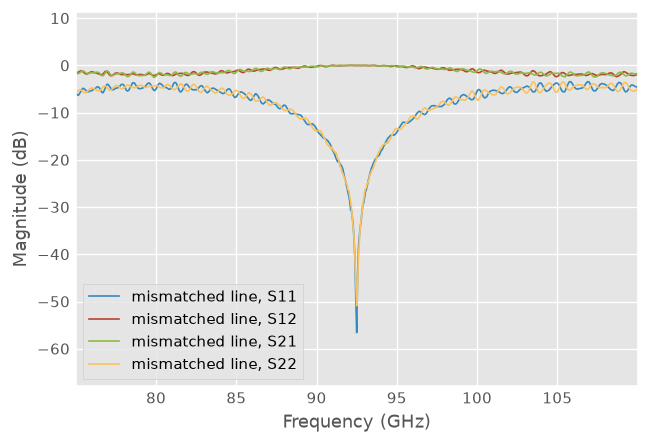

In [4]:
dut_raw = rf.Network('trl_data/mismatched line.s2p')
dut_corrected = trl.apply_cal(dut_raw)
dut_corrected.plot_s_db()

## Switch Terms

### What are they?

Described in [1] by Roger Marks, switch-terms account for the fact that the 8-term (aka error-box ) model is overly simplified. The two error networks change slightly depending on which port is being excited. This is due to the internal switch within the VNA. The change in reflection coefficient at the VNA's internal switch is known as a *switch term*, it  can be directed measured and removed.

* [1] R.B. Marks, "Formulations of the Basic Vector Network Analyzer Error Model including Switch-Terms," in ARFTG Conference Digest-Fall, 50th, 1997, vol. 32, pp. 115-126

### How do I get them ?

To measure the switch terms manually, you can define custom traces as ratio's of receivers and save the data to touchstone files. Assume ports are labeled 1 and 2, and incident waves are a's and reflected waves are b's. Then, the 

* **forward switch term** == `a2/b2` with `source port 1`
* **reverse switch term** == `a1/b1` with `source port 2`



### Can I get them with skrf? 

Yes. There is a PNA driver in the `skrf.vi.vna module`. It has code to pull the switch terms.

### Can get them Onboard  a PNA?
Yes. See the image below for an example of setting this up on a PNA.

<img src="switch_term_dialog.png" width="800"/>